In [266]:

import pandas as pd
from sklearn.preprocessing import  RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import  accuracy_score,f1_score
from sklearn.ensemble import RandomForestClassifier
df = pd.read_csv("dataset.csv")


In [267]:
df = df.drop(labels=df[df.Level.isna()].index) #removing rows where HDI is NaN
#dropping country name , its not a predictor
df = df.drop(columns=["Country"])
X = df.drop(columns =["Level"])
Y = df.Level
x_trv,x_te,y_trv,y_te = train_test_split(X,Y,random_state=10,stratify=Y,test_size=0.2)
#We will use this x_trv and y_trv later for cross validation
x_tr,x_v,y_tr,y_v = train_test_split(x_trv,y_trv,random_state=10,stratify=y_trv,test_size=0.2)
print("Percentages of each class are-")
print(f"For train set\n{y_tr.value_counts()/len(y_tr)*100}\nFor validation set\n{y_v.value_counts()/len(y_v)*100}\
      \nFor test set\n{y_te.value_counts()/len(y_te)*100}")

Percentages of each class are-
For train set
Level
1.0    47.967480
2.0    38.211382
0.0    13.821138
Name: count, dtype: float64
For validation set
Level
1.0    48.387097
2.0    38.709677
0.0    12.903226
Name: count, dtype: float64      
For test set
Level
1.0    48.717949
2.0    38.461538
0.0    12.820513
Name: count, dtype: float64


The class count percentages (The class are 1,2,3 values of Level) are approximately the same across train,test and validation sets

Compared to Mean imputation Median imputation is more resistant to outliers, for example, if the highest value in a category becomes orders of magnitude higher than the rest, the mean increases greatly but theres no change to the median. As such we went with median imputation (our data has many outliers)\
But, it is possible that a value being missing is important information to predict the HDI, to account for this possibility, we are adding missing indicators, i.e for each numerical column, we are adding another column where each missing value gets a '1' and rest of the rows are '0'.


In [268]:
num_cols = x_tr.select_dtypes(include='number').columns
medians = [x_tr[col].median() for col in num_cols] # we found medians wrt train set
def impute_num(data,median):
    for col in num_cols:
        data[col+"missing"] = data[col].isna().astype(int) # adding missingness indicators
    data[num_cols] = data[num_cols].fillna(dict(zip(num_cols,median)))
impute_num(x_tr,medians)
impute_num(x_te,medians)
impute_num(x_v,medians)

In [269]:
cat_cols = x_tr.select_dtypes(exclude='number').columns
dummy_cols = pd.get_dummies(x_tr,columns = cat_cols).columns
def impute_col(data,dummies):
    data[cat_cols] = data[cat_cols].fillna("Missing")
    data = pd.get_dummies(data,columns = cat_cols)
    data = data.reindex(columns=dummies,fill_value=0) #dealing with unseen categories
    return data
x_tr= impute_col(x_tr,dummy_cols)
x_te=impute_col(x_te,dummy_cols)
x_v=impute_col(x_v,dummy_cols)

In [270]:
#Check if any NaNs remaining
x_tr.isna().sum()+ x_v.isna().sum()+ x_te.isna().sum()

Agriculture                              0
Industry                                 0
Services                                 0
Access_to_electricity                    0
Inflation_consumer_prices                0
Individuals_using_the_Internet           0
Trade                                    0
GDP_Growth                               0
Unemployment_total                       0
Infant_mortality                         0
Agriculturemissing                       0
Industrymissing                          0
Servicesmissing                          0
Access_to_electricitymissing             0
Inflation_consumer_pricesmissing         0
Individuals_using_the_Internetmissing    0
Trademissing                             0
GDP_Growthmissing                        0
Unemployment_totalmissing                0
Infant_mortalitymissing                  0
Region_AS                                0
Region_EAP                               0
Region_ECA                               0
Region_LAC 

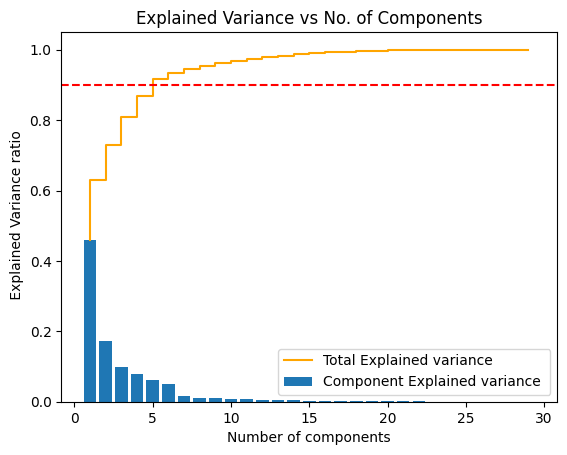

In [271]:
n = len(x_tr.columns)
LR_pipe = Pipeline ([("prep", ColumnTransformer([("num",RobustScaler(),num_cols)], remainder="passthrough")),("model",LogisticRegression())]) # currently doesnt scale binary values
PCA_pipe = Pipeline ([("prep", ColumnTransformer([("num",RobustScaler(),num_cols)], remainder="passthrough")),("model",PCA(n_components=n))]) # currently doesnt scale binary values

components =PCA_pipe.fit_transform(x_tr)
explained_var = PCA_pipe["model"].explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)
plt.bar(list(range(1,n+1)), explained_var,label = "Component Explained variance ")
plt.step(list(range(1,n+1)),cumulative_var, color = "orange",label="Total Explained variance")
plt.legend()
plt.xlabel("Number of components")
plt.title("Explained Variance vs No. of Components")
plt.ylabel(" Explained Variance ratio")
plt.axhline(y=0.9, color= "red", linestyle="--")
plt.show()




In [272]:
principal_loading = pd.DataFrame()
for i in range(10):
 comp = np.abs(PCA_pipe["model"].components_[i])
 ind =np.argpartition(comp,-5)[-5:]
 ind = ind[np.argsort(comp[ind],descending=True)]
 principal_loading[f"PC{i+1}"] = x_tr.columns[ind]
principal_loading #Each column contains the top 5 features which contributed the most to that component

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
0,Inflation_consumer_prices,Access_to_electricity,GDP_Growth,Unemployment_total,Industry,Trade,Agriculture,Inflation_consumer_pricesmissing,Region_LAC,Infant_mortality
1,Trade,Individuals_using_the_Internet,Unemployment_total,GDP_Growth,Services,Industry,Access_to_electricity,Dominant_Sector_Services,Trademissing,Region_SSA
2,GDP_Growth,Infant_mortality,Trade,Access_to_electricity,Trade,Access_to_electricity,Services,Infant_mortality,Individuals_using_the_Internet,Region_EAP
3,Agriculture,Agriculture,Agriculture,Infant_mortality,Access_to_electricity,GDP_Growth,Infant_mortality,Industrymissing,Infant_mortality,Agriculture
4,Unemployment_total,Services,Industry,Industry,Individuals_using_the_Internet,Services,Region_EAP,Servicesmissing,Region_ECA,Trademissing


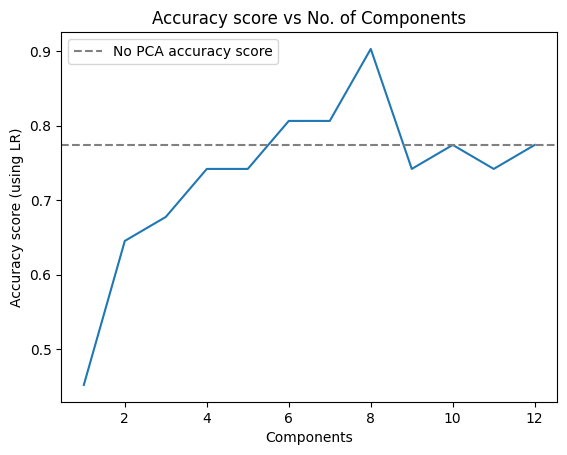

In [273]:

LR_pipe.fit(x_tr,y_tr)
y_no_pca = LR_pipe.predict(x_v)




pca_data = PCA_pipe.transform(x_v)
model = LogisticRegression() #we dont use the pipeline sinc PCA pipeline handles scaling
accuracies = []
for i in range(1,13): # after 15 its too many components
     model = LogisticRegression()
     model.fit(components[:,0:i],y_tr)
     y_pca = model.predict(pca_data[:,0:i])
     accuracies.append(accuracy_score(y_v,y_pca))

plt.plot(list(range(1,13)),accuracies)
plt.xlabel("Components")
plt.ylabel("Accuracy score (using LR)")
plt.axhline(accuracy_score(y_v,y_no_pca), color="grey",linestyle = "--",label="No PCA accuracy score")
plt.legend()
plt.title("Accuracy score vs No. of Components")
plt.show()


We compared the accuracy score of No PCA vs different number of components using PCA. To calculate the accruacy score we used LR and fit it on training set and predicted on the validation set
N=8 is the ideal value of components since it gave high accuracy at a lower value of N

In [274]:

PCA_pipe = Pipeline ([("prep", ColumnTransformer([("num",RobustScaler(),num_cols)], remainder="passthrough")),("model",PCA(n_components=0.9))]) 
x_pca = PCA_pipe.fit_transform(x_tr)
x_pca_v = PCA_pipe.transform(x_v)
#Now our data is scaled and with reduced dimensions
def majority(y_tr,x_v):
   majority = np.unique_counts(y_tr).values[np.argmax(np.unique_counts(y_tr).counts)]
   pred = np.ones(len(x_v))
   return majority*pred
print(f"Majority class macro f1 score is {f1_score(y_v, majority(y_tr,x_pca_v),average="macro"):.2f}")

LR_model = LogisticRegression()
LR_model.fit(x_pca,y_tr)
print(f"Multinomial Logistic Regression macro f1 score is  {f1_score(y_v, LR_model.predict(x_pca_v),average="macro"):.2f} ")
Tree_model = DecisionTreeClassifier()
Tree_model.fit(x_pca,y_tr)
print(f"Decision Tree macro f1 score is  {f1_score(y_v, Tree_model.predict(x_pca_v),average="macro"):.2f} ")
RFC_model = RandomForestClassifier()
RFC_model.fit(x_pca,y_tr)
print(f"Random Forest macro f1 score is  {f1_score(y_v, RFC_model.predict(x_pca_v),average="macro"):.2f} ")

Majority class macro f1 score is 0.22
Multinomial Logistic Regression macro f1 score is  0.82 
Decision Tree macro f1 score is  0.60 
Random Forest macro f1 score is  0.63 


In [275]:
def cross_valid(model,folds):
    F1_scores = []
    for i in range(folds):
        x_tr,x_v,y_tr,y_v = train_test_split(x_trv,y_trv,random_state=10+i,stratify=y_trv,test_size=0.2)
        #For each fold we get a different x_tr and x_v split from the earlier x_trv(x_trv does not contain the test data)
        medians = [x_tr[col].median() for col in num_cols] #num_col and cat_col remain the same regardless of x_tr
        impute_num(x_tr,medians)
        impute_num(x_v,medians)
        dummy_cols = pd.get_dummies(x_tr,columns = cat_cols).columns
        x_tr = impute_col(x_tr,dummy_cols)
        x_v = impute_col(x_v,dummy_cols)
        PCA_pipe = Pipeline ([("prep", ColumnTransformer([("num",RobustScaler(),num_cols)], remainder="passthrough")),("model",PCA(n_components=0.9))])
        model.fit(PCA_pipe.fit_transform(x_tr),y_tr)
        pred = model.predict(PCA_pipe.transform(x_v))
        score = f1_score(y_v,pred,average="macro")
        F1_scores.append(score)
    return [np.mean(F1_scores), np.std(F1_scores)]

cross_valid(LogisticRegression(),4)

[np.float64(0.7644587201846), np.float64(0.06734521861294632)]

In [276]:
#Point 3


In [289]:
x_num = x_tr[num_cols]
cat_cols_new = x_tr.columns[~np.isin(x_tr.columns,num_cols)] #different from original cat_cols due to OHE
x_cat = x_tr[cat_cols_new]
x_num_pca = PCA_pipe.fit_transform(x_num)
LR_model.fit(x_num_pca,y_tr)
x_num_v = PCA_pipe.transform(x_v[num_cols])
print(f"Numerical only LR F1 score is {f1_score(y_v,LR_model.predict(x_num_v),average="macro")}")

pca_cat = PCA(n_components=0.9) #We dont need to scale features so we dont use the PCA pipe
x_cat_pca = pca_cat.fit_transform(x_cat)
LR_model.fit(x_cat_pca,y_tr)
x_cat_v = pca_cat.transform(x_v[cat_cols_new])
print(f"Categorical only LR F1 score is {f1_score(y_v,LR_model.predict(x_cat_v),average="macro")}")

x_combined_pca = PCA_pipe.fit_transform(x_tr)
LR_model.fit(x_combined_pca,y_tr)
x_combined_v = PCA_pipe.transform(x_v)
print(f"Combined LR F1 score is {f1_score(y_v,LR_model.predict(x_combined_v),average="macro")}")



Numerical only LR F1 score is 0.7939560439560439
Categorical only LR F1 score is 0.48323092677931384
Combined LR F1 score is 0.8192239858906526


In [281]:
x_cat

,Agriculturemissing,Industrymissing,Servicesmissing,Access_to_electricitymissing,Inflation_consumer_pricesmissing,Individuals_using_the_Internetmissing,Trademissing,GDP_Growthmissing,Unemployment_totalmissing,Infant_mortalitymissing,Region_AS,Region_EAP,Region_ECA,Region_LAC,Region_SA,Region_SSA,Dominant_Sector_Agriculture,Dominant_Sector_Industry,Dominant_Sector_Services
11,0,0,0,0,0,0,0,0,0,0,False,False,False,True,False,False,False,False,True
31,1,1,1,0,0,0,0,0,0,0,False,False,False,False,False,False,False,False,False
113,0,0,0,0,1,0,0,0,1,0,False,True,False,False,False,False,False,False,True
160,0,0,0,0,0,0,0,0,0,0,False,True,False,False,False,False,False,False,True
101,0,0,0,0,0,0,0,0,0,0,False,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
154,0,0,0,0,0,0,0,0,0,0,False,False,True,False,False,False,False,False,True
133,0,0,0,0,0,0,0,0,1,0,False,True,False,False,False,False,False,False,True
85,0,0,0,0,0,0,0,0,0,0,False,False,False,False,False,False,False,False,True
151,0,0,0,0,0,0,0,0,0,0,False,False,False,False,False,True,False,False,True
